In [ ]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

In [ ]:
Afloor      = 10 * 10
V           = Afloor * 4
HT          = 207
HVsup       = 146
HVie        = 13
H           = HT + HVsup + HVie
Qhnom       = H * 30

c_eff_Whm3K = 15           # Wh/m3-K (Heavy: 50, Light : 15)
C_eff_WhK   = V * c_eff_Whm3K
C           = 3600 * C_eff_WhK # J/K

tau_h       = C_eff_WhK / H
tau         = C / H

round(tau_h,1), round(tau/3600,1)

In [ ]:
timestep = 600 # s

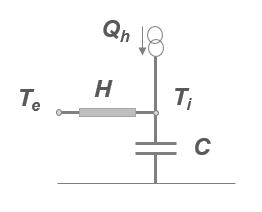

## Night set back - No heat input

In [ ]:
n_days  = 5
n_hours = 24 * n_days
ts      = 3600 * np.arange(0, n_hours, timestep/3600)
hr      = ts /(3600)

Te      = 0 
Qh      = 0

Tinit   = 20

def dT_t (Ti, t):
    dTi_t = H * (Te - Ti) / C + Qh / C
    return dTi_t

Ti = odeint(dT_t, Tinit, ts)

plt.xlabel('hour [h]')
plt.ylabel('Ti [°C]')
plt.grid(linestyle = 'dotted')
plt.vlines(tau_h, 0, 20, linestyle = 'dotted')
plot = plt.plot(hr, Ti, color = 'C0', linewidth=4);

## Restart - Constant heat input

In [ ]:
n_days  = 5
n_hours = 24 * n_days
ts      = 3600 * np.arange(0, n_hours, timestep/3600)
hr      = ts /(3600)

Te      = 0 
Qh      = Qhnom 

Tinit   = 0

def dT_t (Ti, t):
    dTi_t = H * (Te - Ti) / C + Qh / C
    return dTi_t

Ti = odeint(dT_t, Tinit, ts)

plt.xlabel('hour [h]')
plt.ylabel('Ti [°C]')
plt.grid(linestyle = 'dotted')
# plt.hlines(20, 0, 20, linestyle = 'dotted')
plt.vlines(tau_h, 0, 20, linestyle = 'dotted')
plot = plt.plot(hr, Ti, color = 'C0', linewidth=4);

## Restart - Controled heat input

In [ ]:
def f(x) :
    return 1 / (1 + np.exp(-x/0.125))

x = np.linspace(-1, 1, 200) 
y = np.array([f(xi) for xi in x])

plt.figure(figsize = (5,3))
plt.grid(linestyle = 'dotted')
plt.xlabel('Tset - Ti  (°C)')
plt.ylabel('Q / Qmax  (-)')
plt.plot(x, y, color = 'C3', linewidth=4);

In [ ]:
n_days  = 5
n_hours = 24 * n_days
ts      = 3600 * np.arange(0, n_hours, timestep/3600)
hr      = ts /(3600)

Te      = 0 
Qhmax   = Qhnom 
Tset    = 20

def Qh(Ti):
    Xh = 1/(1 + np.exp( (Ti - Tset)/0.125 ) )
    Qh = Xh * Qhmax
    return Qh

Tinit     = 0

def dT_t (Ti, t):
    dTi_t = H * (Te - Ti) / C + Qh(Ti) /C
    return dTi_t

Ti = odeint(dT_t, Tinit, ts)


plt.xlabel('hour [h]')
plt.ylabel('Ti [°C]')
plt.grid(linestyle = 'dotted')
plot = plt.plot(hr, Ti, color = 'C0', linewidth=4);

In [ ]:
Qhi = [Qh(Tii) for Tii in Ti]

plt.xlabel('hour [h]')
plt.ylabel('Qh [W]')
plt.grid(linestyle = 'dotted')
plot = plt.plot(hr, Qhi, color = 'C1', linewidth=4);